# Project: Social Media Marketing Campaign Analytics
### Welcome & Business Context
This project analyzes a dataset of **6,000+ social media campaigns** to answer one fundamental business question:

> **"How can a company improve the performance of its social media campaigns and use its marketing budget more efficiently?"**

The analysis follows a professional analytics workflow: data quality audit → data cleaning → feature engineering → marketing KPIs → exploratory data analysis → 5 business questions → key findings → recommendations.

**Objective:** turn raw campaign data into actionable insights for a marketing team: which platforms perform best, which content types convert, where the budget becomes inefficient, and how spend should be reallocated.

**Tools:** Python (Pandas, NumPy, Matplotlib/Plotly), SQL, Looker Studio.

---
### Phase 1: Data Quality Audit
Before modifying any data, this phase inspects the raw dataset to understand its structure and detect quality issues. It covers dimensions, column names, data types, missing values, exact duplicates, categorical inconsistencies, impossible values, metric consistency and outliers.

No data is modified in this phase — every finding is documented so that the cleaning decisions in Phase 2 are justified by evidence.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Data Ingestion

df_campaigns = pd.read_excel('db/social_media_campaigns_messy_Raw (1).xlsx')
print("DataFrame created successfully")

# Checking the dataframe format and column names

display(df_campaigns.head())
print("\nFirst 5 rows")

display(df_campaigns.tail())
print("\nLast 5 rows")


DataFrame created successfully


,Campaign_ID,Platform,Campaign_Name,Start_Date,End_Date,Spend,Impressions,Clicks,CTR (%),CPC (USD),Conversions,Revenue,Audience_AgeGroup,Audience_Location,Device,Post_Type
0,CAMP3763,TikTok,Campaign_112,2023-05-26,2024-01-07,NaN,249945,7720.0,11.14,6.81,3198.0,7528.46,55+,New York,Tablet,Text
1,CAMP5340,Facebook,Campaign_174,2023-11-05,2023-01-18,3353.44,124311,17601.0,11.34,9.89,4759.0,17247.49,18-24,New York,Mobile,Image
2,CAMP3157,Facebook,Campaign_150,2023-10-04,2024-01-04,1394.15,14714,23856.0,9.43,4.12,4018.0,17751.81,25-34,Abuja,Desktop,Image
3,CAMP4526,Instagram,Campaign_102,2023-12-31,2023-06-30,3769.29,39079,45274.0,8.14,0.38,935.0,6388.99,45-54,Abuja,Tablet,Video
4,CAMP4878,IG,Campaign_140,2023-08-21,2023-09-15,3524.67,33822,30944.0,2.84,3.53,1909.0,9809.53,55+,Toronto,Tablet,Video



First 5 rows


,Campaign_ID,Platform,Campaign_Name,Start_Date,End_Date,Spend,Impressions,Clicks,CTR (%),CPC (USD),Conversions,Revenue,Audience_AgeGroup,Audience_Location,Device,Post_Type
6195,CAMP1110,Twitter,Campaign_104,2023-05-15,2023-07-04,NaN,26346,30699.0,10.47,1.74,1383.0,10486.05,55+,Toronto,Mobile,Image
6196,CAMP5622,TikTok,Campaign_103,2023-08-29,2023-02-24,2758.87,5225,32315.0,1.72,4.73,4050.0,12628.05,25-34,Abuja,Mobile,Video
6197,CAMP3901,TikTok,Campaign_2,2023-06-26,2023-10-29,3217.66,148483,44680.0,1.86,8.55,3254.0,910.80,45-54,London,Tablet,Carousel
6198,CAMP3746,IG,Campaign_93,2023-11-15,2023-09-08,2517.65,471476,39308.0,2.71,4.97,1289.0,7845.52,35-44,New York,Tablet,Video
6199,CAMP4812,YouTube,Campaign_54,2023-12-12,2023-07-23,1809.94,288267,48309.0,9.11,5.44,2105.0,15905.25,35-44,London,Mobile,Text



Last 5 rows


In [2]:
# Checking for missing data or wrong data types

print("Dataframe information: ")
df_campaigns.info()
print("\n")
nulls = df_campaigns.isnull().sum()

errors = pd.DataFrame({
    'Null values': nulls
})

print("Missing values per column:")
print(errors[errors['Null values'] > 0])
print("\nExact duplicate rows:", df_campaigns.duplicated().sum())


Dataframe information: 
<class 'pandas.DataFrame'>
RangeIndex: 6200 entries, 0 to 6199
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Campaign_ID        6200 non-null   str           
 1   Platform           6200 non-null   str           
 2   Campaign_Name      6200 non-null   str           
 3   Start_Date         6200 non-null   datetime64[us]
 4   End_Date           6200 non-null   datetime64[us]
 5   Spend              5888 non-null   float64       
 6   Impressions        6200 non-null   int64         
 7   Clicks             5898 non-null   float64       
 8   CTR (%)            6200 non-null   float64       
 9   CPC (USD)          6200 non-null   float64       
 10  Conversions        5886 non-null   float64       
 11  Revenue            5895 non-null   float64       
 12  Audience_AgeGroup  6200 non-null   str           
 13  Audience_Location  6200 non-null   str           


In [3]:
# Dimensions of the dataset (rows, columns)

print("Shape (rows, columns):")
print(df_campaigns.shape)

# Column names
print("\n Column names:")
print(df_campaigns.columns.tolist())

# Cardinality: unique value count per categorical column

categorical_cols = ["Campaign_ID", "Platform", "Campaign_Name", "Audience_AgeGroup", "Audience_Location", "Device", "Post_Type"]

print("\nUnique value count per categorical column")
print(df_campaigns[categorical_cols].nunique())

Shape (rows, columns):
(6200, 16)

 Column names:
['Campaign_ID', 'Platform', 'Campaign_Name', 'Start_Date', 'End_Date', 'Spend', 'Impressions', 'Clicks', 'CTR (%)', 'CPC (USD)', 'Conversions', 'Revenue', 'Audience_AgeGroup', 'Audience_Location', 'Device', 'Post_Type']

Unique value count per categorical column
Campaign_ID          6000
Platform               14
Campaign_Name         200
Audience_AgeGroup       5
Audience_Location       6
Device                  3
Post_Type               4
dtype: int64


---
### Phase 2: Data Cleaning
With the audit findings documented, this phase transforms the raw dataset into an analysis-ready table. All work is done on a copy (`df_clean`), so the raw data stays untouched. Every change is justified by Phase 1 evidence: platform labels are normalized (14 variants map to 6 platforms), exact duplicate rows are investigated, dates are validated, and missing values are treated according to their pattern.

No data is discarded without justification.

In [4]:
# Creating a working copy so the raw data stays untouched

df_clean = df_campaigns.copy()

# Normalizing Platform names (Phase 1 found 14 variants of the same 6 platforms)

platform_map = {
    "facebook": "Facebook",
    "instagram": "Instagram",
    "ig": "Instagram",
    "tiktok": "TikTok",
    "twitter": "Twitter",
    "youtube": "YouTube",
    "email": "Email"
}

df_clean["Platform"] = df_clean["Platform"].str.strip().str.lower().replace(platform_map)

print("Platforms before:")
print(df_campaigns["Platform"].nunique())

print("\nPlatforms after:")
print(df_clean["Platform"].nunique())
print(sorted(df_clean["Platform"].unique()))


Platforms before:
14

Platforms after:
6
['Email', 'Facebook', 'Instagram', 'TikTok', 'Twitter', 'YouTube']


In [5]:
# Verifying Device and Post_Type before deciding (Phase 1 found no variants, double-checking hidden spaces)

print("Device values:")
print(df_clean["Device"].unique())

print("\nPost_Type values:")
print(df_clean["Post_Type"].unique())

print("\nValues with leading or trailing spaces (Device, Post_Type):")
print((df_clean["Device"] != df_clean["Device"].str.strip()).sum())
print((df_clean["Post_Type"] != df_clean["Post_Type"].str.strip()).sum())

# Conclusion: both columns are clean, no transformation applied


Device values:
<StringArray>
['Tablet', 'Mobile', 'Desktop']
Length: 3, dtype: str

Post_Type values:
<StringArray>
['Text', 'Image', 'Video', 'Carousel']
Length: 4, dtype: str

Values with leading or trailing spaces (Device, Post_Type):
0
0


In [6]:
# Investigating duplicate rows (Phase 1 found 200 exact duplicates and 200 repeated Campaign_IDs)

print("Exact duplicate rows:")
print(df_clean.duplicated().sum())

print("\nRows sharing Campaign_ID with another row:")
print(df_clean.duplicated(subset=["Campaign_ID"], keep=False).sum())

# Checking if repeated Campaign_IDs carry different data or are fully identical rows

dup_ids = df_clean[df_clean.duplicated(subset=["Campaign_ID"], keep=False)].sort_values("Campaign_ID")

print("\nRepeated Campaign_ID groups:")
print(dup_ids["Campaign_ID"].nunique())

print("\nRows per repeated Campaign_ID:")
print(dup_ids.groupby("Campaign_ID").size().unique())

print("\nRepeated groups with fully identical rows:")
print((dup_ids.groupby("Campaign_ID").nunique(dropna=False) == 1).all().all())

# Note: nunique with dropna=False counts NaN as a value, so truly identical rows compare equal

# Conclusion: repeated Campaign_IDs are exact copies, dropping one of each pair

rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("\nRows before and after dropping exact duplicates:")
print(rows_before)
print(len(df_clean))

print("\nRows sharing Campaign_ID after cleaning:")
print(df_clean.duplicated(subset=["Campaign_ID"], keep=False).sum())


Exact duplicate rows:
200

Rows sharing Campaign_ID with another row:
400

Repeated Campaign_ID groups:
200

Rows per repeated Campaign_ID:
[2]

Repeated groups with fully identical rows:
True

Rows before and after dropping exact duplicates:
6200
6000

Rows sharing Campaign_ID after cleaning:
0


In [7]:
# Validating dates (already datetime, checking that ranges make sense)

print("Start_Date range:")
print(df_clean["Start_Date"].min())
print(df_clean["Start_Date"].max())

print("\nRows where End_Date is before Start_Date:")
print((df_clean["End_Date"] < df_clean["Start_Date"]).sum())

# Conclusion: too many rows to drop, both columns are kept and the issue is documented as a limitation


Start_Date range:
2023-01-01 00:00:00
2023-12-31 00:00:00

Rows where End_Date is before Start_Date:
2739


In [8]:
# Verifying precomputed metrics against their definitions (Clicks / Impressions, Spend / Clicks)

check = df_clean[["Clicks", "Impressions", "Spend"]].notnull().all(axis=1)

recalc_ctr = df_clean["Clicks"] / df_clean["Impressions"] * 100
recalc_cpc = df_clean["Spend"] / df_clean["Clicks"]

print("Rows where all inputs are present:")
print(check.sum())

print("\nCTR (%) values matching Clicks / Impressions:")
print((abs(recalc_ctr[check] - df_clean.loc[check, "CTR (%)"]) < 0.01).sum())

print("\nCPC (USD) values matching Spend / Clicks:")
print((abs(recalc_cpc[check] - df_clean.loc[check, "CPC (USD)"]) < 0.01).sum())

# Conclusion: precomputed columns are unreliable, they are dropped and recomputed in the KPI phase

df_clean = df_clean.drop(columns=["CTR (%)", "CPC (USD)"])


Rows where all inputs are present:
5422

CTR (%) values matching Clicks / Impressions:
3

CPC (USD) values matching Spend / Clicks:
6


In [9]:
# Checking impossible values (negatives, Clicks above Impressions)

print("Negative values (Spend, Impressions, Clicks, Conversions, Revenue):")
print((df_clean[["Spend", "Impressions", "Clicks", "Conversions", "Revenue"]] < 0).sum().sum())

print("\nRows where Clicks are greater than Impressions:")
print((df_clean["Clicks"] > df_clean["Impressions"]).sum())

# Conclusion: no negatives found, conflicting rows are kept and documented as a data quality issue


Negative values (Spend, Impressions, Clicks, Conversions, Revenue):
0

Rows where Clicks are greater than Impressions:
271


In [10]:
# Reviewing missing values pattern before deciding (imputing money metrics would invent results)

print("Rows by count of missing values in Spend, Clicks, Conversions, Revenue:")
print(df_clean[["Spend", "Clicks", "Conversions", "Revenue"]].isnull().sum(axis=1).value_counts().sort_index())

# Conclusion: missing values are isolated single-column gaps, they are kept as NaN without imputation


Rows by count of missing values in Spend, Clicks, Conversions, Revenue:
0    4900
1    1006
2      88
3       6
Name: count, dtype: int64


In [11]:
# Checking outliers in money metrics with the IQR method

print(df_clean[["Spend", "Impressions", "Revenue"]].describe().round(2))

for col in ["Spend", "Impressions", "Revenue"]:
    s = df_clean[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    outside = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"\n{col} values outside IQR fences:")
    print(outside)

# Conclusion: values fall inside the IQR fences, no outliers to remove


         Spend  Impressions   Revenue
count  5700.00      6000.00   5700.00
mean   2519.53    251378.72  10025.44
std    1420.36    144258.76   5750.26
min      50.59      1018.00    100.33
25%    1316.32    127816.50   5088.27
50%    2534.22    250161.50   9928.56
75%    3728.23    373796.25  15069.82
max    4999.09    499863.00  19999.45

Spend values outside IQR fences:
0

Impressions values outside IQR fences:
0

Revenue values outside IQR fences:
0


In [12]:
# Converting whole-number metrics with gaps to nullable integers

df_clean["Clicks"] = df_clean["Clicks"].astype("Int64")
df_clean["Conversions"] = df_clean["Conversions"].astype("Int64")

print("Dataframe information: ")
df_clean.info()


Dataframe information: 
<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Campaign_ID        6000 non-null   str           
 1   Platform           6000 non-null   str           
 2   Campaign_Name      6000 non-null   str           
 3   Start_Date         6000 non-null   datetime64[us]
 4   End_Date           6000 non-null   datetime64[us]
 5   Spend              5700 non-null   float64       
 6   Impressions        6000 non-null   int64         
 7   Clicks             5700 non-null   Int64         
 8   Conversions        5700 non-null   Int64         
 9   Revenue            5700 non-null   float64       
 10  Audience_AgeGroup  6000 non-null   str           
 11  Audience_Location  6000 non-null   str           
 12  Device             6000 non-null   str           
 13  Post_Type          6000 non-null   str           


In [13]:
# Saving the cleaned dataset

from pathlib import Path

Path("../data/cleaned").mkdir(parents=True, exist_ok=True)
df_clean.to_csv("../data/cleaned/social_media_campaigns_clean.csv", index=False)

print("Cleaned rows and columns:")
print(df_clean.shape)


Cleaned rows and columns:
(6000, 14)


---
### Phase 3: Marketing KPIs
Phase 2 proved the precomputed CTR and CPC columns wrong, so they were removed. This phase rebuilds the six core marketing metrics from their definitions on the cleaned data: CTR, CPC, Conversion Rate, CPA, ROAS and ROI. Ratios are stored as decimals (0.03 means 3%) and shown as percentages when reported. Divisions by zero (CPA with zero conversions) are marked as missing, never invented.

In [14]:
# Recalculating marketing KPIs from their definitions (precomputed columns were dropped in Phase 2)

import numpy as np

df_clean["CTR"] = df_clean["Clicks"] / df_clean["Impressions"]
df_clean["CPC"] = df_clean["Spend"] / df_clean["Clicks"]
df_clean["Conversion_Rate"] = df_clean["Conversions"] / df_clean["Clicks"]
df_clean["CPA"] = df_clean["Spend"] / df_clean["Conversions"]
df_clean["ROAS"] = df_clean["Revenue"] / df_clean["Spend"]
df_clean["ROI"] = (df_clean["Revenue"] - df_clean["Spend"]) / df_clean["Spend"]

# CPA is undefined when Conversions are zero, marking that case as missing

df_clean["CPA"] = df_clean["CPA"].replace([np.inf, -np.inf], np.nan)

print("KPI columns:")
print(["CTR", "CPC", "Conversion_Rate", "CPA", "ROAS", "ROI"])


KPI columns:
['CTR', 'CPC', 'Conversion_Rate', 'CPA', 'ROAS', 'ROI']


In [15]:
# Reviewing the recalculated KPIs

display(df_clean[["Campaign_ID", "Platform", "Spend", "Impressions", "Clicks", "Conversions", "Revenue", "CTR", "CPC", "Conversion_Rate", "CPA", "ROAS", "ROI"]].head())
print("\nFirst 5 rows with KPIs")

print("\nKPI summary:")
print(df_clean[["CTR", "CPC", "Conversion_Rate", "CPA", "ROAS", "ROI"]].describe().round(2))

print("\nRows with CTR above 100% (Clicks above Impressions):")
print((df_clean["CTR"] > 1).sum())

print("\nRows with negative ROI (Revenue below Spend):")
print((df_clean["ROI"] < 0).sum())


,Campaign_ID,Platform,Spend,Impressions,Clicks,Conversions,Revenue,CTR,CPC,Conversion_Rate,CPA,ROAS,ROI
0,CAMP3763,TikTok,NaN,249945,7720,3198,7528.46,0.030887,<NA>,0.414249,<NA>,NaN,NaN
1,CAMP5340,Facebook,3353.44,124311,17601,4759,17247.49,0.141588,0.190526,0.270382,0.704652,5.143223,4.143223
2,CAMP3157,Facebook,1394.15,14714,23856,4018,17751.81,1.621313,0.05844,0.168427,0.346976,12.733070,11.733070
3,CAMP4526,Instagram,3769.29,39079,45274,935,6388.99,1.158525,0.083255,0.020652,4.031326,1.695012,0.695012
4,CAMP4878,Instagram,3524.67,33822,30944,1909,9809.53,0.914907,0.113905,0.061692,1.846344,2.783106,1.783106



First 5 rows with KPIs

KPI summary:


          CTR     CPC  Conversion_Rate      CPA     ROAS      ROI
count  5700.0  5422.0           5416.0   5417.0  5417.00  5417.00
mean     0.33    0.35             0.34     3.69     9.48     8.48
std      1.39    2.07             1.79    23.02    21.72    21.72
min       0.0     0.0              0.0     0.01     0.03    -0.97
25%      0.05    0.05             0.05     0.51     2.01     1.01
50%       0.1     0.1              0.1     1.02     4.00     3.00
75%       0.2    0.21              0.2     2.09     7.83     6.83
max      32.5   94.34             65.2  1041.94   343.95   342.95

Rows with CTR above 100% (Clicks above Impressions):
271

Rows with negative ROI (Revenue below Spend):
678


---
### Exploratory Data Analysis
Before answering the business questions, this phase maps the overall landscape: total investment and return, the shape of the key metric distributions, and how spend relates to results. Every chart here answers one question about the data as a whole.

In [16]:
# Overall totals (the big picture before digging deeper)

print("Total Spend:")
print(df_clean["Spend"].sum().round(2))

print("\nTotal Revenue:")
print(df_clean["Revenue"].sum().round(2))

print("\nTotal Impressions:")
print(df_clean["Impressions"].sum())

print("\nTotal Clicks:")
print(df_clean["Clicks"].sum())

print("\nTotal Conversions:")
print(df_clean["Conversions"].sum())

print("\nOverall ROAS (Total Revenue / Total Spend):")
print((df_clean["Revenue"].sum() / df_clean["Spend"].sum()).round(2))

print("\nOverall CPA (Total Spend / Total Conversions):")
print((df_clean["Spend"].sum() / df_clean["Conversions"].sum()).round(2))


Total Spend:
14361313.21

Total Revenue:
57145008.85

Total Impressions:
1508272325

Total Clicks:
141424641

Total Conversions:
14204765

Overall ROAS (Total Revenue / Total Spend):
3.98

Overall CPA (Total Spend / Total Conversions):
1.01


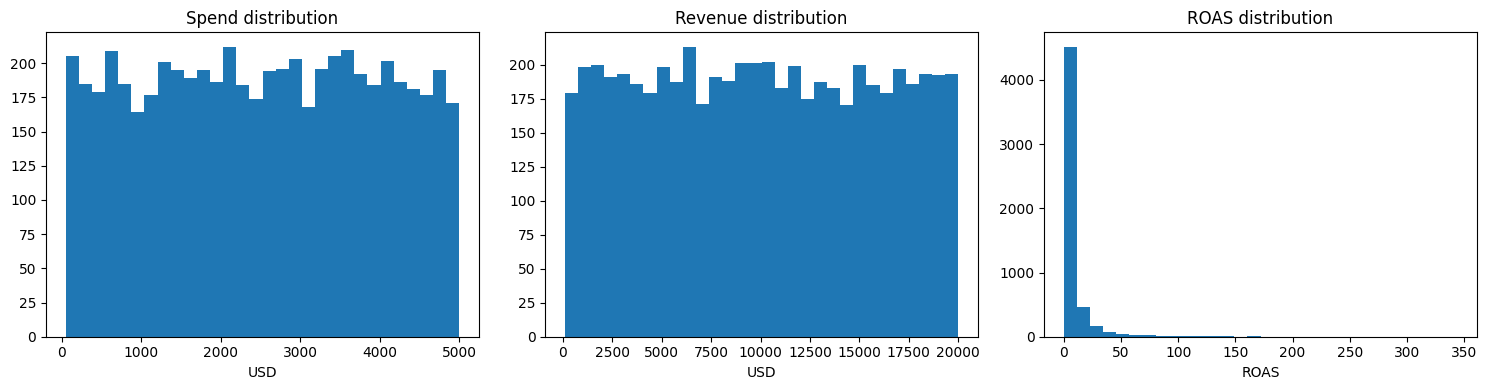

In [17]:
# Distributions of Spend, Revenue and ROAS (are results concentrated or spread out?)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df_clean["Spend"].dropna(), bins=30)
axes[0].set_title("Spend distribution")
axes[0].set_xlabel("USD")

axes[1].hist(df_clean["Revenue"].dropna(), bins=30)
axes[1].set_title("Revenue distribution")
axes[1].set_xlabel("USD")

axes[2].hist(df_clean["ROAS"].dropna(), bins=30)
axes[2].set_title("ROAS distribution")
axes[2].set_xlabel("ROAS")

plt.tight_layout()
plt.show()


In [18]:
# Correlations between spend and results (does spending more buy more?)

print("Correlation matrix (Spend, Impressions, Clicks, Conversions, Revenue):")
print(df_clean[["Spend", "Impressions", "Clicks", "Conversions", "Revenue"]].corr().round(2))


Correlation matrix (Spend, Impressions, Clicks, Conversions, Revenue):
             Spend  Impressions  Clicks  Conversions  Revenue
Spend         1.00        -0.02   -0.00        -0.01    -0.02
Impressions  -0.02         1.00   -0.01         0.03     0.02
Clicks       -0.00        -0.01    1.00        -0.01    -0.01
Conversions  -0.01         0.03   -0.01         1.00    -0.00
Revenue      -0.02         0.02   -0.01        -0.00     1.00


---
### Business Question 1: Platform Efficiency
> **"Which platforms deliver the best balance between investment, conversions and economic return?"**

Platforms are compared by totals and overall ratios (ROAS, CPA, ROI computed on aggregated Spend, Conversions and Revenue), never by simple averages, which outliers would distort. Volume alone decides nothing.

In [19]:
# Comparing platforms by totals (averages would be distorted by outliers)

platform_perf = df_clean.groupby("Platform").agg(
    Spend=("Spend", "sum"),
    Clicks=("Clicks", "sum"),
    Conversions=("Conversions", "sum"),
    Revenue=("Revenue", "sum"),
    Campaigns=("Campaign_ID", "count")
)

platform_perf["ROAS"] = (platform_perf["Revenue"] / platform_perf["Spend"]).round(2)
platform_perf["CPA"] = (platform_perf["Spend"] / platform_perf["Conversions"]).round(2)
platform_perf["ROI"] = ((platform_perf["Revenue"] - platform_perf["Spend"]) / platform_perf["Spend"]).round(2)

print("Platform performance (totals and overall ratios):")
print(platform_perf.sort_values("ROAS", ascending=False).round(2))


Platform performance (totals and overall ratios):
                Spend    Clicks  Conversions      Revenue  Campaigns  ROAS  \
Platform                                                                     
Email      1962797.56  19603896      2042923   8184667.66        831  4.17   
Twitter    1875309.27  19557893      1975352   7610387.75        812  4.06   
Facebook   2033729.80  19481643      2019908   8173764.37        854  4.02   
TikTok     2078301.29  19781791      2035686   8207483.73        855  3.95   
Instagram  4199443.42  41196511      3978184  16533558.49       1739  3.94   
YouTube    2211731.87  21802907      2152712   8435146.85        909  3.81   

            CPA   ROI  
Platform               
Email      0.96  3.17  
Twitter    0.95  3.06  
Facebook   1.01  3.02  
TikTok     1.02  2.95  
Instagram  1.06  2.94  
YouTube    1.03  2.81  


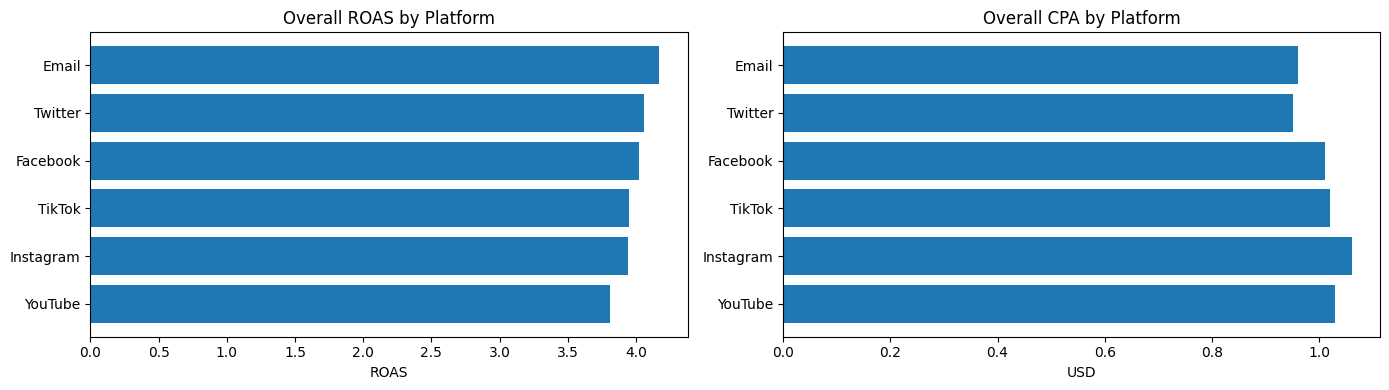

In [20]:
# Charting efficiency (which platform returns most per dollar spent?)

plot_data = platform_perf.sort_values("ROAS", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].barh(plot_data.index, plot_data["ROAS"])
axes[0].set_title("Overall ROAS by Platform")
axes[0].set_xlabel("ROAS")

axes[1].barh(plot_data.index, plot_data["CPA"])
axes[1].set_title("Overall CPA by Platform")
axes[1].set_xlabel("USD")

plt.tight_layout()
plt.show()


---
### Business Question 2: Content Performance
> **"Which content types deliver the best results, and on which platforms do they work best?"**

Content types are compared by overall ratios, and every Platform and Post_Type combination is mapped. The most-seen content is not assumed to be the best.

In [21]:
# Comparing content types by totals (most impressions does not mean best)

content_perf = df_clean.groupby("Post_Type").agg(
    Spend=("Spend", "sum"),
    Impressions=("Impressions", "sum"),
    Clicks=("Clicks", "sum"),
    Conversions=("Conversions", "sum"),
    Revenue=("Revenue", "sum"),
    Campaigns=("Campaign_ID", "count")
)

content_perf["ROAS"] = (content_perf["Revenue"] / content_perf["Spend"]).round(2)
content_perf["CTR"] = (content_perf["Clicks"] / content_perf["Impressions"]).round(4)
content_perf["ConvRate"] = (content_perf["Conversions"] / content_perf["Clicks"]).round(4)

print("Content performance (totals and overall ratios):")
print(content_perf.sort_values("ROAS", ascending=False).round(4))


Content performance (totals and overall ratios):
                Spend  Impressions    Clicks  Conversions      Revenue  \
Post_Type                                                                
Text       3641327.07    374953577  35166324      3573003  14871808.99   
Video      3751712.65    395717767  37949243      3716779  15059816.36   
Carousel   3556523.00    382270708  34508171      3626679  14043597.53   
Image      3411750.49    355330273  33800903      3288304  13169785.97   

           Campaigns  ROAS     CTR  ConvRate  
Post_Type                                     
Text            1498  4.08  0.0938    0.1016  
Video           1572  4.01  0.0959    0.0979  
Carousel        1504  3.95  0.0903    0.1051  
Image           1426  3.86  0.0951    0.0973  


In [22]:
# Mapping ROAS for every Platform and Post_Type combination

combo = df_clean.groupby(["Platform", "Post_Type"]).agg(
    Spend=("Spend", "sum"),
    Revenue=("Revenue", "sum")
)
combo["ROAS"] = (combo["Revenue"] / combo["Spend"]).round(2)
combo_roas = combo["ROAS"].unstack()

print("Overall ROAS by Platform and Post_Type:")
print(combo_roas)

print("\nBest combination:")
print(combo.sort_values("ROAS", ascending=False).head(3))

print("\nWorst combination:")
print(combo.sort_values("ROAS").head(3))


Overall ROAS by Platform and Post_Type:
Post_Type  Carousel  Image  Text  Video
Platform                               
Email          3.54   3.98  4.43   4.66
Facebook       4.18   3.74  4.64   3.58
Instagram      4.13   4.01  3.90   3.72
TikTok         3.86   3.97  4.16   3.82
Twitter        3.94   4.01  3.82   4.40
YouTube        3.85   3.40  3.79   4.25

Best combination:
                        Spend     Revenue  ROAS
Platform Post_Type                             
Email    Video      513374.27  2393229.33  4.66
Facebook Text       485485.20  2250342.00  4.64
Email    Text       519129.93  2299652.57  4.43

Worst combination:
                        Spend     Revenue  ROAS
Platform Post_Type                             
YouTube  Image      565162.43  1920206.70  3.40
Email    Carousel   474281.28  1676903.44  3.54
Facebook Video      549989.47  1970722.58  3.58


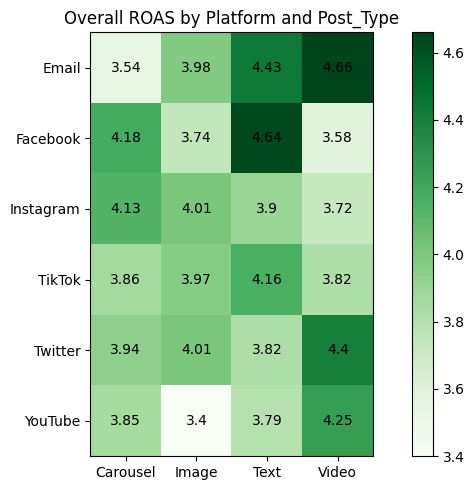

In [23]:
# Charting the best combinations (where does each content type work best?)

fig, ax = plt.subplots(figsize=(8, 5))
heat = ax.imshow(combo_roas, cmap="Greens")
ax.set_xticks(range(len(combo_roas.columns)))
ax.set_yticks(range(len(combo_roas.index)))
ax.set_xticklabels(combo_roas.columns)
ax.set_yticklabels(combo_roas.index)
ax.set_title("Overall ROAS by Platform and Post_Type")

for i in range(len(combo_roas.index)):
    for j in range(len(combo_roas.columns)):
        ax.text(j, i, combo_roas.iloc[i, j], ha="center", va="center")

plt.colorbar(heat)
plt.tight_layout()
plt.show()


---
### Business Question 3: Budget Efficiency
> **"Is there a point where increasing ad spend stops generating proportional results?"**

Campaigns are grouped by spend range and each range is judged by overall ratios plus its share of total spend versus its share of total revenue.

In [24]:
# Grouping campaigns by spend range (does spending more buy proportionally more?)

df_clean["Spend_bin"] = pd.cut(
    df_clean["Spend"],
    bins=[0, 1000, 2000, 3000, 4000, 5000],
    labels=["0-1k", "1k-2k", "2k-3k", "3k-4k", "4k-5k"]
)

spend_perf = df_clean.groupby("Spend_bin", observed=True).agg(
    Spend=("Spend", "sum"),
    Revenue=("Revenue", "sum"),
    Conversions=("Conversions", "sum"),
    Campaigns=("Campaign_ID", "count")
)

spend_perf["ROAS"] = (spend_perf["Revenue"] / spend_perf["Spend"]).round(2)
spend_perf["CPA"] = (spend_perf["Spend"] / spend_perf["Conversions"]).round(2)
spend_perf["Spend_share"] = (spend_perf["Spend"] / spend_perf["Spend"].sum()).round(3)
spend_perf["Revenue_share"] = (spend_perf["Revenue"] / spend_perf["Revenue"].sum()).round(3)

print("Performance by spend range:")
print(spend_perf)


Performance by spend range:
                Spend      Revenue  Conversions  Campaigns   ROAS   CPA  \
Spend_bin                                                                 
0-1k        561844.84  10330196.44      2528993       1088  18.39  0.22   
1k-2k      1713360.92  11014661.65      2770490       1140   6.43  0.62   
2k-3k      2960255.87  11435969.64      2802907       1184   3.86  1.06   
3k-4k      4079218.24  11067242.14      2768152       1164   2.71  1.47   
4k-5k      5046633.34  10634592.49      2621538       1124   2.11  1.93   

           Spend_share  Revenue_share  
Spend_bin                              
0-1k             0.039          0.190  
1k-2k            0.119          0.202  
2k-3k            0.206          0.210  
3k-4k            0.284          0.203  
4k-5k            0.351          0.195  


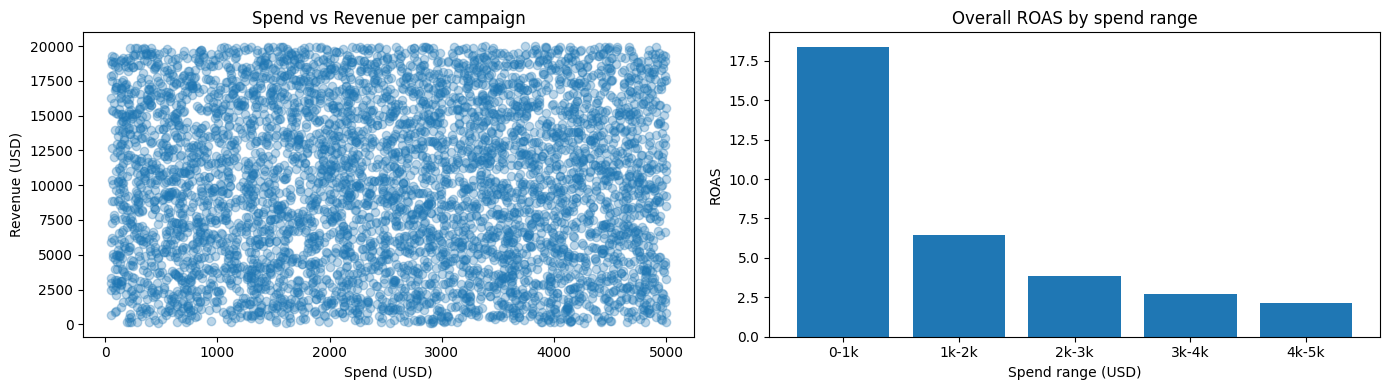

In [25]:
# Charting diminishing returns (revenue stays flat while spend grows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].scatter(df_clean["Spend"], df_clean["Revenue"], alpha=0.3)
axes[0].set_title("Spend vs Revenue per campaign")
axes[0].set_xlabel("Spend (USD)")
axes[0].set_ylabel("Revenue (USD)")

axes[1].bar(spend_perf.index.astype(str), spend_perf["ROAS"])
axes[1].set_title("Overall ROAS by spend range")
axes[1].set_xlabel("Spend range (USD)")
axes[1].set_ylabel("ROAS")

plt.tight_layout()
plt.show()


---
### Business Question 4: Audience and Segmentation
> **"Which audience segments perform best, and which ones consume budget without proportional results?"**

Age group, location and device are compared by totals and overall ratios. Small gaps are reported as small gaps, not as breakthroughs.

In [26]:
# Comparing audience segments by totals (efficient segments vs budget eaters)

for seg in ["Audience_AgeGroup", "Audience_Location", "Device"]:
    seg_perf = df_clean.groupby(seg).agg(
        Spend=("Spend", "sum"),
        Clicks=("Clicks", "sum"),
        Impressions=("Impressions", "sum"),
        Conversions=("Conversions", "sum"),
        Revenue=("Revenue", "sum"),
        Campaigns=("Campaign_ID", "count")
    )

    seg_perf["ROAS"] = (seg_perf["Revenue"] / seg_perf["Spend"]).round(2)
    seg_perf["CPA"] = (seg_perf["Spend"] / seg_perf["Conversions"]).round(2)
    seg_perf["CTR"] = (seg_perf["Clicks"] / seg_perf["Impressions"]).round(4)
    seg_perf["ConvRate"] = (seg_perf["Conversions"] / seg_perf["Clicks"]).round(4)

    print(f"\nSegment performance by {seg}:")
    print(seg_perf.sort_values("ROAS", ascending=False).round(4))



Segment performance by Audience_AgeGroup:
                        Spend    Clicks  Impressions  Conversions  \
Audience_AgeGroup                                                   
35-44              2796488.08  27798894    288576714      2718120   
18-24              3013771.30  29764287    324021395      3051095   
55+                2759160.14  26695392    292450084      2700479   
45-54              2910295.21  28563812    304099683      2798707   
25-34              2881598.48  28602256    299124449      2936364   

                       Revenue  Campaigns  ROAS   CPA     CTR  ConvRate  
Audience_AgeGroup                                                        
35-44              11452773.78       1158  4.10  1.03  0.0963    0.0978  
18-24              12174966.15       1265  4.04  0.99  0.0919    0.1025  
55+                10950812.29       1157  3.97  1.02  0.0913    0.1012  
45-54              11526466.79       1207  3.96  1.04  0.0939     0.098  
25-34              11039989.8

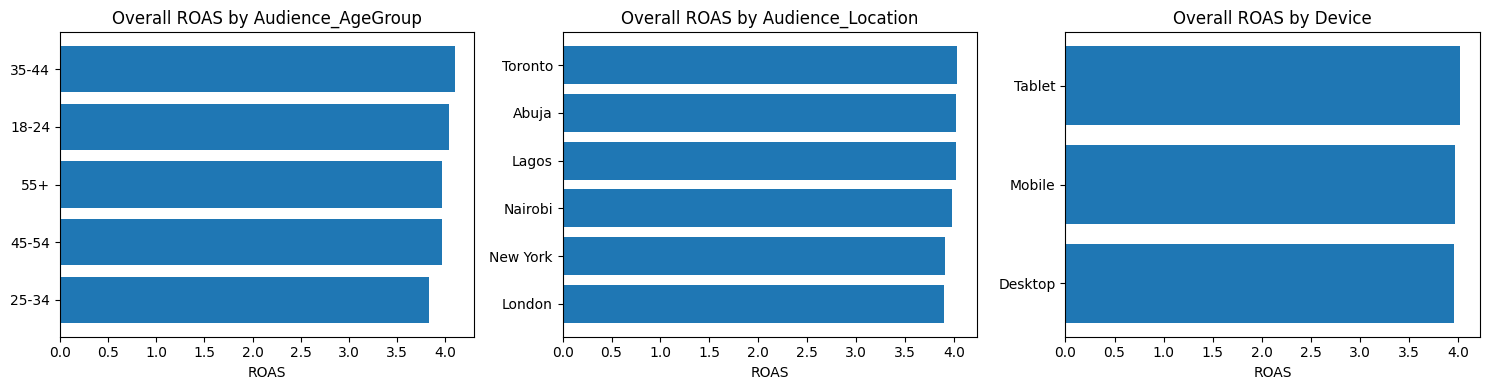

In [27]:
# Charting segment efficiency (any segment far from the rest?)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, seg in zip(axes, ["Audience_AgeGroup", "Audience_Location", "Device"]):
    seg_data = df_clean.groupby(seg).agg(Spend=("Spend", "sum"), Revenue=("Revenue", "sum"))
    seg_roas = (seg_data["Revenue"] / seg_data["Spend"]).sort_values()
    ax.barh(seg_roas.index.astype(str), seg_roas.values)
    ax.set_title(f"Overall ROAS by {seg}")
    ax.set_xlabel("ROAS")

plt.tight_layout()
plt.show()


---
### Business Question 5: Budget Reallocation Opportunity
> **"If the marketing budget had to be redistributed, where are the clear opportunities to improve performance?"**

This synthesis uses Questions 1 to 4. OBSERVED numbers describe what happened. The MODELED scenario below is a what-if exercise with explicit assumptions (bin ROAS stays constant, no saturation, same campaign mix): a scenario, never a guaranteed result.

In [28]:
# OBSERVED: who gets the budget vs who brings the revenue

share = df_clean.groupby("Platform").agg(Spend=("Spend", "sum"), Revenue=("Revenue", "sum"))
share["ROAS"] = (share["Revenue"] / share["Spend"]).round(2)
share["Spend_share"] = (share["Spend"] / share["Spend"].sum()).round(3)
share["Revenue_share"] = (share["Revenue"] / share["Revenue"].sum()).round(3)
share["Gap"] = (share["Revenue_share"] - share["Spend_share"]).round(3)

print("OBSERVED budget vs revenue share by Platform:")
print(share.sort_values("ROAS"))


OBSERVED budget vs revenue share by Platform:
                Spend      Revenue  ROAS  Spend_share  Revenue_share    Gap
Platform                                                                   
YouTube    2211731.87   8435146.85  3.81        0.154          0.148 -0.006
Instagram  4199443.42  16533558.49  3.94        0.292          0.289 -0.003
TikTok     2078301.29   8207483.73  3.95        0.145          0.144 -0.001
Facebook   2033729.80   8173764.37  4.02        0.142          0.143  0.001
Twitter    1875309.27   7610387.75  4.06        0.131          0.133  0.002
Email      1962797.56   8184667.66  4.17        0.137          0.143  0.006


In [29]:
# MODELED SCENARIO: moving 20% of the 4k-5k range spend to low-spend efficiency
# Assumptions: bin ROAS stays constant, no saturation, same campaign mix

low_bin = df_clean[df_clean["Spend_bin"] == "0-1k"]
high_bin = df_clean[df_clean["Spend_bin"] == "4k-5k"]

low_roas = low_bin["Revenue"].sum() / low_bin["Spend"].sum()
high_roas = high_bin["Revenue"].sum() / high_bin["Spend"].sum()

total_revenue = df_clean["Revenue"].sum()
moved_spend = 0.20 * high_bin["Spend"].sum()
modeled_total = total_revenue - moved_spend * high_roas + moved_spend * low_roas

print("OBSERVED total Revenue:")
print(total_revenue.round(2))

print("\nMoved Spend (20% of the 4k-5k range):")
print(moved_spend.round(2))

print("\nMODELED total Revenue under the scenario:")
print(modeled_total.round(2))

print("\nMODELED uplift vs OBSERVED:")
print(str(round((modeled_total / total_revenue - 1) * 100, 1)) + "%")


OBSERVED total Revenue:
57145008.85

Moved Spend (20% of the 4k-5k range):
1009326.67

MODELED total Revenue under the scenario:
73575781.04

MODELED uplift vs OBSERVED:
28.8%


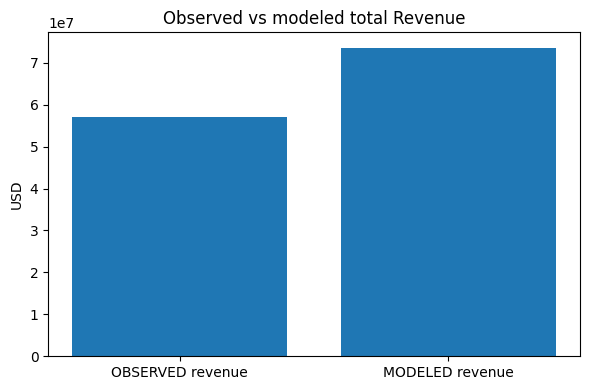

In [30]:
# Charting the scenario (how large is the modeled opportunity?)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["OBSERVED revenue", "MODELED revenue"], [total_revenue, modeled_total])
ax.set_title("Observed vs modeled total Revenue")
ax.set_ylabel("USD")
plt.tight_layout()
plt.show()


---
### Key Findings
1. **Email is the most efficient platform** (overall ROAS 4.17, ROI 3.17), with Twitter second (ROAS 4.06, lowest CPA 0.95). YouTube ranks last (ROAS 3.81).
2. **Volume is not efficiency:** Instagram runs twice the campaigns (1,739) of any other platform but sits mid-table (ROAS 3.94).
3. **Text is the best content type** (ROAS 4.08) while Video gathers the most impressions (395M) without leading on return (ROAS 4.01).
4. **Best combination: Email + Video** (ROAS 4.66), followed by Facebook + Text (4.64). Worst: YouTube + Image (3.40).
5. **Carousel converts best** (overall Conversion Rate 0.1051) **but monetizes average** (ROAS 3.95): converting and earning are different skills.
6. **Spend efficiency collapses with budget size:** the 0-1k range holds 3.9% of spend and 19.0% of revenue (ROAS 18.39), while the 4k-5k range holds 35.1% of spend for 19.5% of revenue (ROAS 2.11).
7. **Segments show no meaningful gaps:** age ROAS ranges 3.83-4.10 (best 35-44), location 3.90-4.04 (best Toronto), device 3.95-4.02 (best Tablet).
8. **Platforms are budget-balanced:** revenue share tracks spend share within 0.006 for every channel; misallocation lives in spend size, not in channel choice.
9. **Modeled scenario (not a promise):** moving 20% of the 4k-5k range spend to low-spend efficiency would lift total revenue from $57.15M to $73.58M (+28.8%) under constant-ROAS assumptions.

---
### Recommendations
* **Cap high-spend campaigns and test low-spend patterns.** WHAT: pilot shifting budget from the 4k-5k range toward sub-1k campaign structures. WHY: observed ROAS falls from 18.39 to 2.11 as spend grows (Q3).
* **Prioritize Email for conversion goals, with Video creative.** WHAT: allocate conversion-oriented budget to Email + Video and Facebook + Text first. WHY: the two best observed combinations, ROAS 4.66 and 4.64 (Q1, Q2).
* **Fix YouTube + Image before funding it.** WHAT: audit creative and targeting of that combination instead of scaling it. WHY: lowest observed combo ROAS at 3.40 (Q2).
* **Do not reallocate by age, location or device.** WHAT: keep segment budgets proportional until stronger evidence appears. WHY: gaps are noise-level across all three variables (Q4).
* **Measure efficiency with overall ratios, not averages.** WHAT: report ROAS/CPA computed on totals in every dashboard. WHY: simple averages are inflated by outliers (mean ROAS 9.48 vs overall 3.98).

In [31]:
# Saving the final cleaned dataset with KPIs and segments
# (base file keeps its name, post-analysis gets its own file: never overwrite)

df_clean.to_csv("../data/cleaned/social_media_campaigns_with_kpis.csv", index=False)

print("Final cleaned rows and columns:")
print(df_clean.shape)

print("\nFinal columns:")
print(df_clean.columns.tolist())


Final cleaned rows and columns:
(6000, 21)

Final columns:
['Campaign_ID', 'Platform', 'Campaign_Name', 'Start_Date', 'End_Date', 'Spend', 'Impressions', 'Clicks', 'Conversions', 'Revenue', 'Audience_AgeGroup', 'Audience_Location', 'Device', 'Post_Type', 'CTR', 'CPC', 'Conversion_Rate', 'CPA', 'ROAS', 'ROI', 'Spend_bin']


---
### Robustness Check: Star Finding
The strongest finding (Q3) is re-tested on the 4,900 fully complete rows only. If it holds without the NaN rows, it is real and reportable.

In [32]:
# Robustness check: does the star finding hold on fully complete rows only?

complete = df_clean.dropna(subset=["Spend", "Clicks", "Conversions", "Revenue"])

print("Fully complete rows:")
print(len(complete))

print("\nSpend-range ROAS on fully complete rows:")
cc_perf = complete.groupby("Spend_bin", observed=True).agg(Spend=("Spend", "sum"), Revenue=("Revenue", "sum"))
cc_perf["ROAS"] = (cc_perf["Revenue"] / cc_perf["Spend"]).round(2)
cc_perf["Spend_share"] = (cc_perf["Spend"] / cc_perf["Spend"].sum()).round(3)
cc_perf["Revenue_share"] = (cc_perf["Revenue"] / cc_perf["Revenue"].sum()).round(3)
print(cc_perf)

print("\nEmail + Video ROAS on fully complete rows:")
ev = complete[(complete["Platform"] == "Email") & (complete["Post_Type"] == "Video")]
print((ev["Revenue"].sum() / ev["Spend"].sum()).round(2))


Fully complete rows:
4900

Spend-range ROAS on fully complete rows:
                Spend      Revenue   ROAS  Spend_share  Revenue_share
Spend_bin                                                            
0-1k        478014.64   9291732.90  19.44        0.039          0.189
1k-2k      1445262.95   9825833.83   6.80        0.116          0.200
2k-3k      2581033.37  10406319.78   4.03        0.208          0.212
3k-4k      3508603.03   9941519.89   2.83        0.283          0.202
4k-5k      4401708.79   9654506.15   2.19        0.355          0.197

Email + Video ROAS on fully complete rows:
4.42


---
### Star Finding
> **"Campaigns spending under $1k concentrate just 3.9% of the budget and generate 19.0% of total revenue."**
>
> Business implication: efficiency lives at low spend. Scaling budget without changing campaign structure buys proportionally less return.

Confirmed on fully complete rows (ROAS 19.44 vs 18.39 on full data) and consistent with the modeled +28.8% reallocation scenario.